Se crean las anotaciones de no TEJIDO NO ETIQUETADO (no_labeled) y las de FONDO (background)

# Crear Anotaciones con clase 'no_labeled'

Este notebook:
1. Detecta tejido usando HSV thresholding
2. Encuentra áreas de tejido NO anotadas
3. Crea polígonos para esas áreas con clase 'no_labeled'
4. Crea polígonos para fondo
4. Guarda las anotaciones corregidas

In [44]:
import cv2
import numpy as np
import geojson
from shapely.geometry import shape, Polygon
from pathlib import Path
import matplotlib.pyplot as plt
from tqdm import tqdm

In [45]:
DATA = Path("../../data")
DATA_DIR = DATA / "raw"
WSI_DIR = DATA_DIR / "wsi_images"
ANNOT_DIR = DATA_DIR / "annotations_resized"
OUTPUT_DIR = DATA / "processed" / "clean_annotations"
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)

In [47]:
def detect_background_hsv(image, sat_threshold=30, value_threshold=200):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    lower_white = np.array([0, 0, value_threshold])
    upper_white = np.array([180, sat_threshold, 255])
    mask = cv2.inRange(hsv, lower_white, upper_white)
    return mask

def rasterize_annotations(annotations, img_shape):
    h, w = img_shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)
    
    for feature in annotations['features']:
        geom = shape(feature['geometry'])
        
        if geom.geom_type == 'Polygon':
            polys = [geom]
        elif geom.geom_type == 'MultiPolygon':
            polys = list(geom.geoms)
        else:
            continue
        
        for poly in polys:
            ext_coords = np.array(poly.exterior.coords, dtype=np.int32)
            cv2.fillPoly(mask, [ext_coords], 255)
            
            for interior in poly.interiors:
                int_coords = np.array(interior.coords, dtype=np.int32)
                cv2.fillPoly(mask, [int_coords], 0)
    
    return mask

def mask_to_polygons(mask, min_area=1000):
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    polygons = []
    for contour in contours:
        if cv2.contourArea(contour) < min_area:
            continue
        contour = contour.squeeze()
        if len(contour.shape) == 1:
            continue
        coords = [(float(x), float(y)) for x, y in contour]
        if len(coords) >= 3:
            polygons.append(Polygon(coords))
    
    return polygons

def visualize_annotations(img_rgb, annotations, alpha=0.4):
    colors = {
        'Decidua': (255, 0, 0),
        'Labyrinth': (0, 255, 0),
        'Junctional Zone': (0, 0, 255),
        'no_labeled': (255, 255, 0),
        'background': (255, 0, 0)
    }
    
    overlay = img_rgb.copy()
    
    for feature in annotations['features']:
        geom = shape(feature['geometry'])
        class_name = feature['properties'].get('name', 'unknown')
        print(class_name)
        color = colors.get(class_name, (128, 128, 128))
        
        if geom.geom_type == 'Polygon':
            polys = [geom]
        elif geom.geom_type == 'MultiPolygon':
            polys = list(geom.geoms)
        else:
            continue
        
        for poly in polys:
            ext_coords = np.array(poly.exterior.coords, dtype=np.int32)
            cv2.fillPoly(overlay, [ext_coords], color)
            
            for interior in poly.interiors:
                int_coords = np.array(interior.coords, dtype=np.int32)
                cv2.fillPoly(overlay, [int_coords], (0, 0, 0))
    
    result = cv2.addWeighted(img_rgb, 1 - alpha, overlay, alpha, 0)
    
    plt.figure(figsize=(15, 12))
    plt.imshow(result)
    plt.title('Anotaciones Superpuestas')
    plt.axis('off')
    
    legend_elements = [plt.Rectangle((0, 0), 1, 1, facecolor=np.array(c)/255) 
                       for c in colors.values()]
    plt.legend(legend_elements, colors.keys(), loc='upper right')
    plt.show()
    
    return result

## Ejemplo con slide_001

In [38]:
slide_id = "slide_001"

img_path = WSI_DIR / f"{slide_id}.tif"
img = cv2.imread(str(img_path))
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print(f"Imagen: {img.shape}")

annot_path = ANNOT_DIR / f"{slide_id}.geojson"
with open(annot_path, 'r') as f:
    annotations = geojson.load(f)

print(f"Features originales: {len(annotations['features'])}")

background_mask = detect_background_hsv(img, 30, 180)
tissue_mask = cv2.bitwise_not(background_mask)

print(f"Fondo: {np.sum(background_mask > 0) / background_mask.size * 100:.2f}%")
print(f"Tejido: {np.sum(tissue_mask > 0) / tissue_mask.size * 100:.2f}%")

Imagen: (6240, 8686, 3)
Features originales: 6
Fondo: 65.24%
Tejido: 34.76%


In [39]:
annot_mask = rasterize_annotations(annotations, img.shape)
print(f"Anotado: {np.sum(annot_mask > 0) / annot_mask.size * 100:.2f}%")

unlabeled_tissue = cv2.bitwise_and(tissue_mask, cv2.bitwise_not(annot_mask))
print(f"Tejido no anotado: {np.sum(unlabeled_tissue > 0) / unlabeled_tissue.size * 100:.2f}%")

Anotado: 32.72%
Tejido no anotado: 4.88%


In [40]:
# Generar polígonos de tejido no labeleado
unlabeled_polygons = mask_to_polygons(unlabeled_tissue, min_area=5000)
print(f"Polígonos no_labeled: {len(unlabeled_polygons)}")

no_labeled_features = []
for poly in unlabeled_polygons:
    feature = {
        "type": "Feature",
        "properties": {"name": "no_labeled", "class": "no_labeled"},
        "geometry": geojson.loads(geojson.dumps(poly.__geo_interface__))
    }
    no_labeled_features.append(feature)

# Generar polígonos de background no labeleado
unlabeled_background = cv2.bitwise_and(background_mask, cv2.bitwise_not(annot_mask))
background_polygons = mask_to_polygons(unlabeled_background, min_area=10000)
print(f"Polígonos background: {len(background_polygons)}")

background_features = []
for poly in background_polygons:
    feature = {
        "type": "Feature",
        "properties": {"name": "background", "class": "background"},
        "geometry": geojson.loads(geojson.dumps(poly.__geo_interface__))
    }
    background_features.append(feature)

# Combinar todas las features
all_features = annotations['features'] + no_labeled_features + background_features
new_annotations = {"type": "FeatureCollection", "features": all_features}

print(f"Originales: {len(annotations['features'])}, no_labeled: {len(no_labeled_features)}, background: {len(background_features)}, Total: {len(all_features)}")

Polígonos no_labeled: 24
Polígonos background: 2
Originales: 6, no_labeled: 24, background: 2, Total: 32


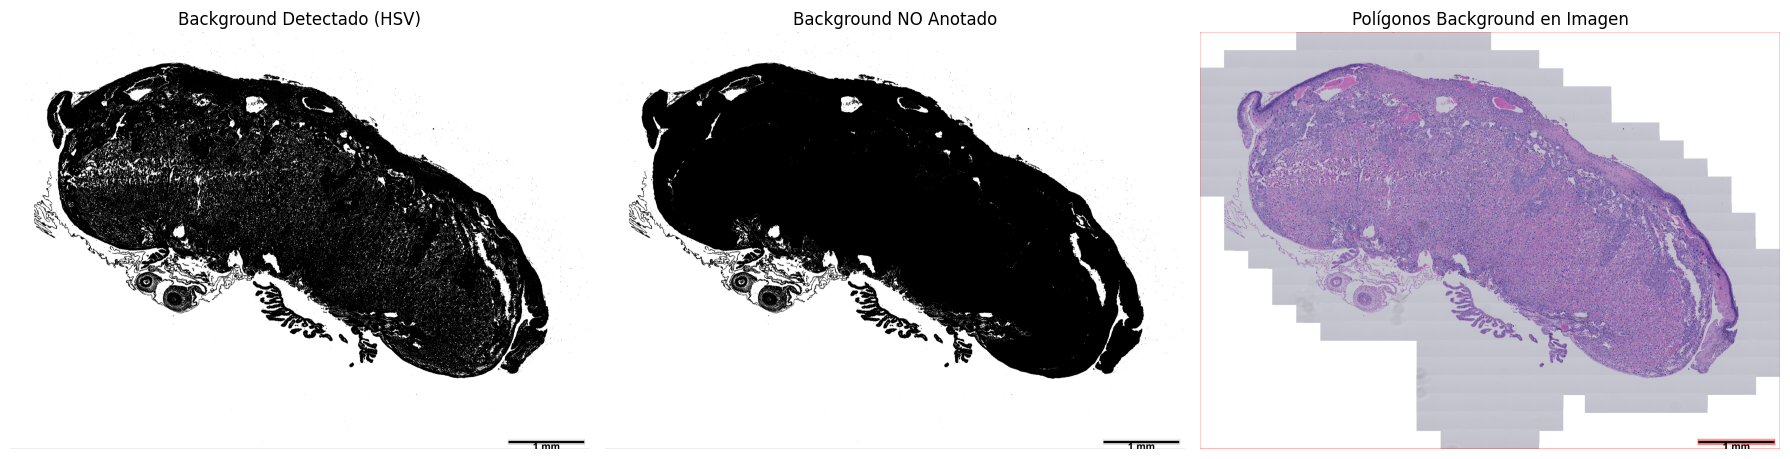

Polígonos de background generados: 2
Área total background no anotado: 62.40%


In [42]:
# Verificar polígonos de background generados
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(background_mask, cmap='gray')
axes[0].set_title('Background Detectado (HSV)')
axes[0].axis('off')

axes[1].imshow(unlabeled_background, cmap='gray')
axes[1].set_title('Background NO Anotado')
axes[1].axis('off')

# Dibujar polígonos de background sobre la imagen
overlay = img_rgb.copy()
for feature in background_features:
    geom = shape(feature['geometry'])
    coords = np.array(geom.exterior.coords, dtype=np.int32)
    cv2.polylines(overlay, [coords], True, (255, 0, 0), 3)

axes[2].imshow(overlay)
axes[2].set_title('Polígonos Background en Imagen')
axes[2].axis('off')

plt.tight_layout()
plt.show()

print(f"Polígonos de background generados: {len(background_features)}")
print(f"Área total background no anotado: {np.sum(unlabeled_background > 0) / unlabeled_background.size * 100:.2f}%")

In [ ]:
visualize_annotations(img_rgb, new_annotations)

In [10]:
output_path = OUTPUT_DIR / f"{slide_id}.geojson"
with open(output_path, 'w') as f:
    geojson.dump(new_annotations, f)
print(f"Guardado: {output_path}")

Guardado: ../../data/processed/clean_annotations/slide_001.geojson


## Procesar todos los slides

In [43]:
def process_slide(slide_id, sat_threshold=30, value_threshold=200, min_area=5000, min_bg_area=10000, save = False):
    img_path = WSI_DIR / f"{slide_id}.tif"
    if not img_path.exists():
        return None
    
    img = cv2.imread(str(img_path))
    
    annot_path = ANNOT_DIR / f"{slide_id}.geojson"
    if not annot_path.exists():
        return None
    
    with open(annot_path, 'r') as f:
        annotations = geojson.load(f)
    
    background_mask = detect_background_hsv(img, sat_threshold, value_threshold)
    tissue_mask = cv2.bitwise_not(background_mask)
    
    #plt.figure(figsize=(10,10))
    #plt.imshow(background_mask,cmap = 'gray')
    #plt.show()
    annot_mask = rasterize_annotations(annotations, img.shape)
    
    unlabeled_tissue = cv2.bitwise_and(tissue_mask, cv2.bitwise_not(annot_mask))
    
    unlabeled_polygons = mask_to_polygons(unlabeled_tissue, min_area=min_area)
    
    no_labeled_features = []
    for poly in unlabeled_polygons:
        feature = {
            "type": "Feature",
            "properties": {"name": "no_labeled", "class": "no_labeled"},
            "geometry": geojson.loads(geojson.dumps(poly.__geo_interface__))
        }
        no_labeled_features.append(feature)
    
    unlabeled_background = cv2.bitwise_and(background_mask, cv2.bitwise_not(annot_mask))
    background_polygons = mask_to_polygons(unlabeled_background, min_area=min_bg_area)
    
    background_features = []
    for poly in background_polygons:
        feature = {
            "type": "Feature",
            "properties": {"name": "background", "class": "background"},
            "geometry": geojson.loads(geojson.dumps(poly.__geo_interface__))
        }
        background_features.append(feature)
    
    all_features = annotations['features'] + no_labeled_features + background_features
    new_annotations = {"type": "FeatureCollection", "features": all_features}
    
    if save:
        output_path = OUTPUT_DIR / f"{slide_id}.geojson"
        with open(output_path, 'w') as f:
            geojson.dump(new_annotations, f)
    
    return {
        'slide_id': slide_id,
        'original_features': len(annotations['features']),
        'no_labeled_features': len(no_labeled_features),
        'background_features': len(background_features),
        'total_features': len(all_features),
        'tissue_pct': np.sum(tissue_mask > 0) / tissue_mask.size * 100,
        'unlabeled_pct': np.sum(unlabeled_tissue > 0) / unlabeled_tissue.size * 100,
        'background_not_annotated_pct': np.sum(unlabeled_background > 0) / unlabeled_background.size * 100
    }

In [49]:
annot_files = sorted(ANNOT_DIR.glob("slide_*.geojson"))
slide_ids = [f.stem for f in annot_files]
SAT_THRESHOLD = 30
VALUE_THRESHOLD = 180
print(f"Procesando {len(slide_ids)} slides...")

results = []
for slide_id in tqdm(slide_ids):
    try:
        result = process_slide(slide_id, SAT_THRESHOLD, VALUE_THRESHOLD,save = True,min_bg_area=5000)
        if result:
            results.append(result)
    except Exception as e:
        print(f"Error {slide_id}: {e}")

Procesando 50 slides...


100%|██████████| 50/50 [01:17<00:00,  1.54s/it]


# Visualize annotations

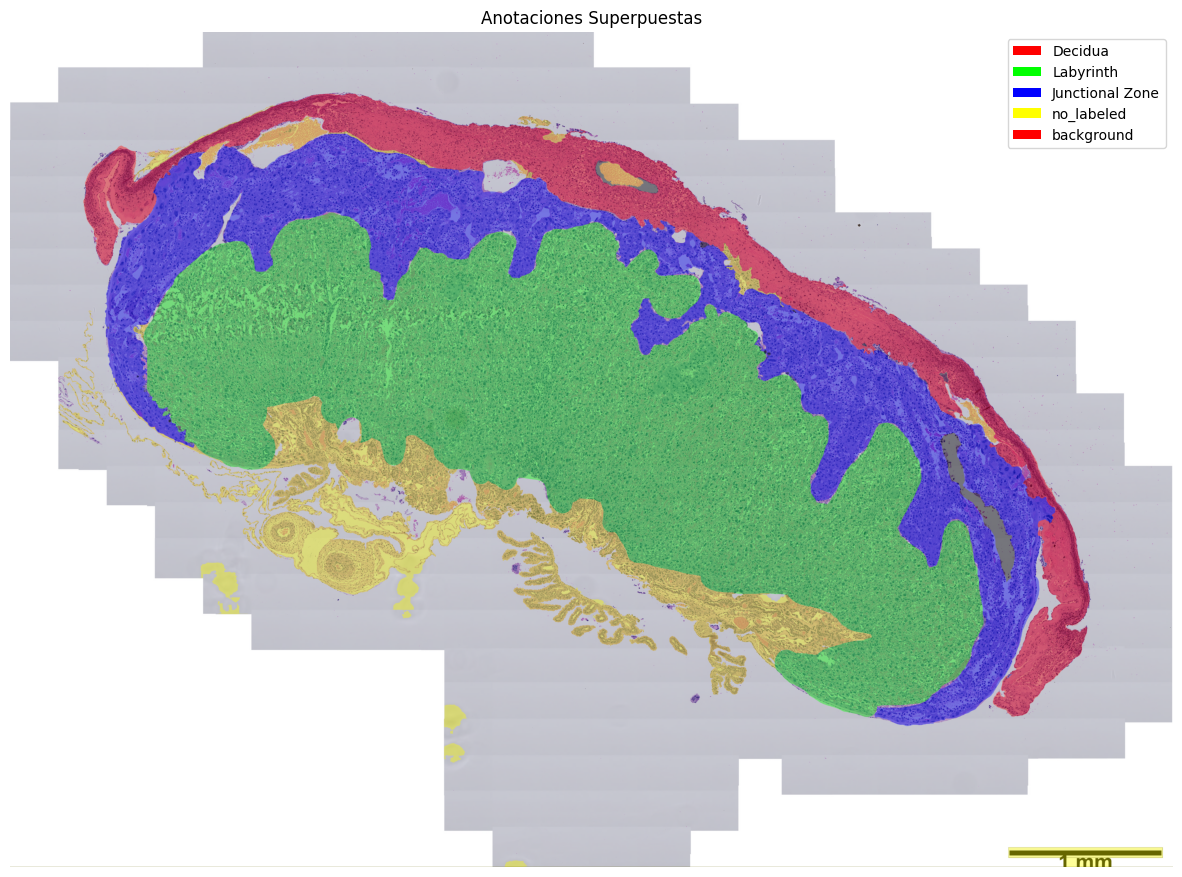

array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[102, 102,   0],
        [102, 102,   0],
        [102, 102,   0],
        ...,
        [102, 102,   0],
        [102, 102,   0],
        [102, 102,   0]]

In [34]:
visualize_annotations(img_rgb, new_annotations)